## AdaBoost Hyperparameter Tuning:

Tunes `AdaBoostClassifier` on noisy concentric circles. The two main knobs are `n_estimators` (how many stumps) and `learning_rate` (it shrinks each stump's weight, so smaller values need more stumps).
We start from the defaults, try a manual change, then search a grid with cross-validation.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

from sklearn.ensemble import AdaBoostClassifier
from sklearn.model_selection import GridSearchCV

from sklearn.model_selection import cross_val_score
from sklearn.datasets import make_circles

## Data:

500 points on two noisy circles, with one class near the centre and the other around it. With `noise=0.35` the classes overlap heavily, so perfect accuracy isn't possible.

In [2]:
np.random.seed(42)
X, y = make_circles(n_samples=500, factor=0.1, noise=0.35, random_state=42)

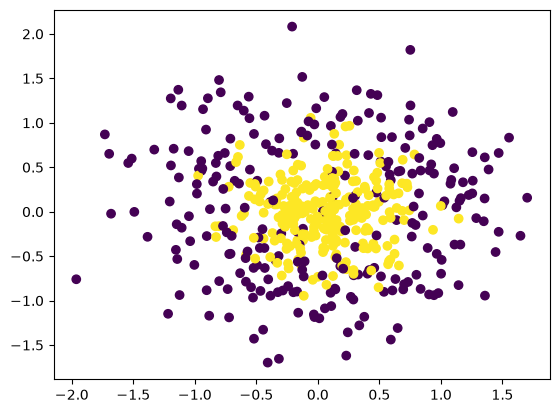

In [3]:
plt.scatter(X[:,0], X[:,1], c=y)

## Baseline:

Default AdaBoost (50 stumps, `learning_rate=1.0`), scored with 10-fold cross-validation. That averages ten train/test splits instead of relying on a single one. Mean accuracy is about 0.786.

In [4]:
ada_boost = AdaBoostClassifier()
np.mean(cross_val_score(ada_boost, X, y, scoring='accuracy', cv=10))

np.float64(0.812)

In [5]:
ada_boost.fit(X,y)

,"estimator estimator: object, default=NoneThe base estimator from which the boosted ensemble is built.Support for sample weighting is required, as well as proper``classes_`` and ``n_classes_`` attributes. If ``None``, thenthe base estimator is :class:`~sklearn.tree.DecisionTreeClassifier`initialized with `max_depth=1`... versionadded:: 1.2 `base_estimator` was renamed to `estimator`.",None
,"n_estimators n_estimators: int, default=50The maximum number of estimators at which boosting is terminated.In case of perfect fit, the learning procedure is stopped early.Values must be in the range `[1, inf)`.",50
,"learning_rate learning_rate: float, default=1.0Weight applied to each classifier at each boosting iteration. A higherlearning rate increases the contribution of each classifier. There isa trade-off between the `learning_rate` and `n_estimators` parameters.Values must be in the range `(0.0, inf)`.",1.0
,"random_state random_state: int, RandomState instance or None, default=NoneControls the random seed given at each `estimator` at eachboosting iteration.Thus, it is only used when `estimator` exposes a `random_state`.Pass an int for reproducible output across multiple function calls.See :term:`Glossary <random_state>`.",None
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels.","ndarray[int64](2,)","[0,1]"
estimator_ estimator_: estimatorThe base estimator from which the ensemble is grown... versionadded:: 1.2 `base_estimator_` was renamed to `estimator_`.,DecisionTreeClassifier,DecisionTreeC...r(max_depth=1)
estimator_errors_ estimator_errors_: ndarray of floatsClassification error for each estimator in the boostedensemble.,"ndarray[float64](50,)","[0.39,0.41,0.38,...,0.48,0.48,0.48]"
estimator_weights_ estimator_weights_: ndarray of floatsWeights for each estimator in the boosted ensemble.,"ndarray[float64](50,)","[0.44,0.34,0.47,...,0.1 ,0.09,0.1 ]"
estimators_ estimators_: list of classifiersThe collection of fitted sub-estimators.,list,"[DecisionTreeC...te=1264648382), DecisionTreeC...te=1312958716), DecisionTreeC...te=1653982164), DecisionTreeC...ate=819956639), ...]"
"feature_importances_ feature_importances_: ndarray of shape (n_features,)The impurity-based feature importances if supported by the``estimator`` (when based on decision trees).Warning: impurity-based feature importances can be misleading forhigh cardinality features (many unique values). See:func:`sklearn.inspection.permutation_importance` as an alternative.","ndarray[float64](2,)","[0.54,0.46]"


## Decision boundary:

The shaded area is the region predicted as the inner class. It is boxy because every stump splits along a single axis.

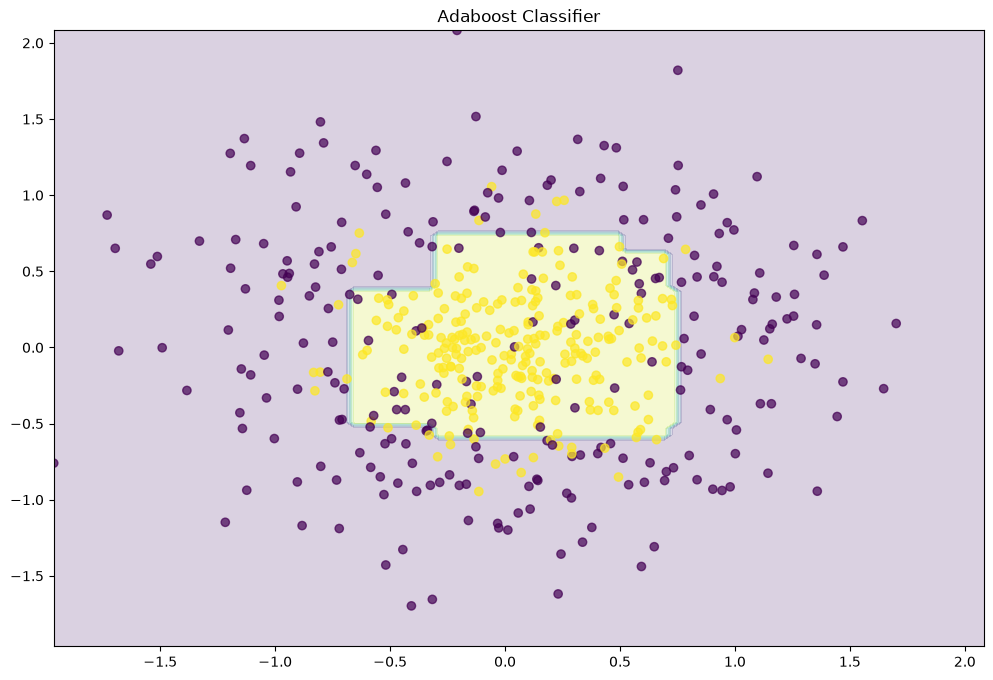

In [6]:
def plot_decision_boundary(clf):
    plt.figure(figsize=(12, 8))
    x_range = np.linspace(X.min(), X.max(), 100)
    xx1, xx2 = np.meshgrid(x_range, x_range)
    y_hat = clf.predict(np.c_[xx1.ravel(), xx2.ravel()])
    y_hat = y_hat.reshape(xx1.shape)
    plt.contourf(xx1, xx2, y_hat, alpha=0.2)
    plt.scatter(X[:,0], X[:,1], c=y, cmap='viridis', alpha=.7)
    plt.title("Adaboost Classifier")
    plt.show()
    
plot_decision_boundary(ada_boost)

## More stumps, smaller learning rate:

1500 stumps with `learning_rate=0.1`. Each stump now carries a tenth of its usual weight, so many more are needed. The boundary looks similar to the default one, with finer detail and a few small pockets around noisy points.

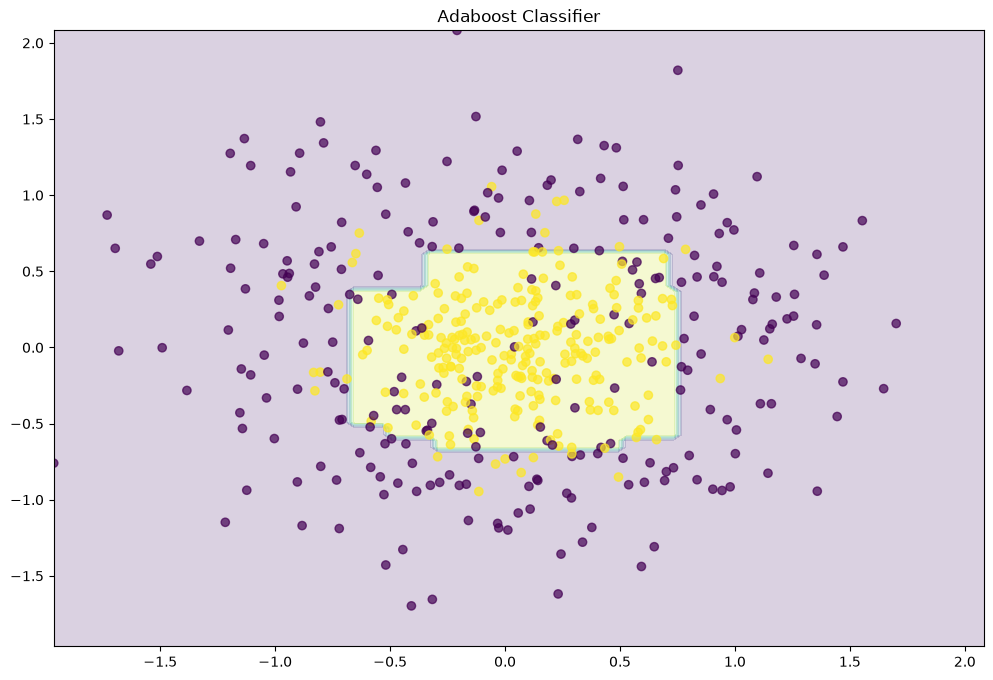

In [7]:
ada_boost = AdaBoostClassifier(n_estimators=1500, learning_rate=0.1)
ada_boost.fit(X, y)
plot_decision_boundary(ada_boost)

## GridSearchCV:

In [8]:
grid = dict()
grid['n_estimators'] = [10, 50, 100, 500]
grid['learning_rate'] = [0.0001, 0.001, 0.01, 0.1, 1.0]

In [9]:
grid_search = GridSearchCV(estimator=AdaBoostClassifier(), param_grid=grid, n_jobs=-1, cv=10, scoring='accuracy')
grid_result = grid_search.fit(X, y)
print("Best: %f using %s" % (grid_result.best_score_, grid_result.best_params_))

Best: 0.832000 using {'learning_rate': 0.1, 'n_estimators': 500}


## Reference:

[Shrinkage parameter in AdaBoost](https://stats.stackexchange.com/questions/82323/shrinkage-parameter-in-adaboost): a discussion of the learning rate (shrinkage) parameter.